**Import Libraries**

In [1]:
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, GRU, Dense
import matplotlib.pyplot as plt

**Load and Preprocess the IMDb Dataset**

In [2]:
num_words = 10000
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=num_words)
max_sequence_length = 500
x_train = pad_sequences(x_train, maxlen=max_sequence_length)
x_test = pad_sequences(x_test, maxlen=max_sequence_length)

**Model Definition and Training (LSTM & GRU)**

In [7]:
# LSTM Model
lstm_model = Sequential([
    Embedding(input_dim=num_words, output_dim=32),
    LSTM(32),
    Dense(1, activation='sigmoid')
])
lstm_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
lstm_history = lstm_model.fit(x_train, y_train, epochs=5, batch_size=256, validation_split=0.2)
lstm_test_loss, lstm_test_accuracy = lstm_model.evaluate(x_test, y_test)

# GRU Model
gru_model = Sequential([
    Embedding(input_dim=num_words, output_dim=32, input_length=max_sequence_length),
    GRU(32),
    Dense(1, activation='sigmoid')
])
gru_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
gru_history = gru_model.fit(x_train, y_train, epochs=5, batch_size=256, validation_split=0.2)
gru_test_loss, gru_test_accuracy = gru_model.evaluate(x_test, y_test)

Epoch 1/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.6139 - loss: 0.6590 - val_accuracy: 0.8190 - val_loss: 0.4427
Epoch 2/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.8443 - loss: 0.3841 - val_accuracy: 0.8566 - val_loss: 0.3385
Epoch 3/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.9062 - loss: 0.2509 - val_accuracy: 0.8554 - val_loss: 0.3507
Epoch 4/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.9252 - loss: 0.2087 - val_accuracy: 0.8600 - val_loss: 0.3222
Epoch 5/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 148s 2s/step - accuracy: 0.9482 - loss: 0.1536 - val_accuracy: 0.8744 - val_loss: 0.3455
782/782 ━━━━━━━━━━━━━━━━━━━━ 110s 140ms/step - accuracy: 0.8587 - loss: 0.3762
Epoch 1/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 177s 2s/step - accuracy: 0.5851 - loss: 0.6697 - val_accuracy: 0.7802 - val_loss: 0.4525
Epoch 2/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 179s 2s/step - accuracy: 0.8512 - loss: 0.3451 - val_accuracy: 0.8572 - val_loss: 0.3395
Epoch 3/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 18

**Plotting Validation Accuracy**

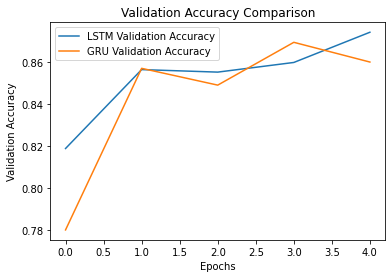

In [8]:
# Plotting validation accuracy for LSTM and GRU
plt.plot(lstm_history.history['val_accuracy'], label='LSTM Validation Accuracy')
plt.plot(gru_history.history['val_accuracy'], label='GRU Validation Accuracy')

plt.title('Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.show()

**Displaying Test Metrics**

In [9]:
# Display test loss and accuracy for LSTM and GRU
print(f'LSTM Test loss: {lstm_test_loss}')
print(f'LSTM Test accuracy: {lstm_test_accuracy}')
print(f'GRU Test loss: {gru_test_loss}')
print(f'GRU Test accuracy: {gru_test_accuracy}')

LSTM Test loss: 0.38143929839134216
LSTM Test accuracy: 0.8572800159454346
GRU Test loss: 0.4296737015247345
GRU Test accuracy: 0.852400004863739
